# Non-Contractual Player Churn Prediction: Multi-Product iGaming Pipeline

## 1. Executive Summary & Problem Formulation
In continuous-play digital gaming platforms, churn is **non-contractual**: players never explicitly cancel an account; they simply disengage, drain balances, or migrate to competing operators.

### 1.1 Objective
Build an end-to-end churn classification pipeline on longitudinal poker and cashier records to identify players at high risk of 45-day activity cessation.

### 1.2 Data Topology
The analysis integrates five relational event streams keyed on `UserID`:
1. **Demographics**: Static user-level attributes (`SystemAgeAsOfReg`, `Gender`, `CountryID`).
2. **Cash Games**: Continuous stake and rake volume (`Windows`, `StakesC`, `WinningsC`).
3. **Tournaments**: Discrete fixed-fee game volume (`Trnmnts`, `StakesT`, `WinningsT`).
4. **Cashier Deposits**: Liquidity inflows and payment gateway health (`Amount`, `Status`, `PayMethCat`).
5. **Cashier Withdrawals**: Capital extraction and cashing-out events (`Amount`, `Status`).

UserID         int64
Date             str
Windows        int64
StakesC      float64
WinningsC    float64
dtype: object


In [41]:
# change date columns to datetime format
for df, columns in (
    (CashGames, ["Date"]),
    (Tournaments, ["Date"]),
    (Deposits, ["SummaryDate", "ProcessDate"]),
    (Withdrawals, ["SummaryDate", "ProcessDate"]),
):
    df[columns] = df[columns].apply(pd.to_datetime)

In [42]:
tables = [
    ("CashGames", CashGames),
    ("Tournaments", Tournaments),
    ("Deposits", Deposits),
    ("Withdrawals", Withdrawals),
]

for name, table in tables:
    print(f"Size of the {name} table is: {table.shape}")

Size of the CashGames table is: (51763, 5)
Size of the Tournaments table is: (82831, 5)
Size of the Deposits table is: (295088, 10)
Size of the Withdrawals table is: (32307, 10)


In [43]:
for name, table in tables:
    print(f'The number of unique players in the {name} table is: {table["UserID"].nunique()}')

The number of unique players in the CashGames table is: 4232
The number of unique players in the Tournaments table is: 3448
The number of unique players in the Deposits table is: 5008
The number of unique players in the Withdrawals table is: 1827


In [44]:
activity_user_ids = pd.concat(
    [
        CashGames["UserID"],
        Tournaments["UserID"],
        Deposits["UserID"],
        Withdrawals["UserID"],
    ],
    ignore_index=True,
).dropna().drop_duplicates()

demographic_user_ids = Demographics["UserID"].dropna().drop_duplicates()

matches = activity_user_ids.isin(demographic_user_ids)
matched_count = matches.sum()
total_count = len(activity_user_ids)

percentage = matched_count / total_count * 100 if total_count else 0

print(f"{matched_count} of {total_count} activity users are in Demographics ({percentage:.2f}%).")

5028 of 5028 activity users are in Demographics (100.00%).


## 2. Temporal Framing & Target Definition

To model non-contractual churn without data leakage, we divide our longitudinal timeline into two non-overlapping windows separated by a fixed cutoff date ($T_{\text{cutoff}}$):

$$\underbrace{\left[ T_{\text{start}},\, T_{\text{cutoff}} \right)}_{\text{Observation Window (Feature Engineering)}} \quad \Bigg| \quad \underbrace{\left[ T_{\text{cutoff}},\, T_{\text{cutoff}} + 45\text{ days} \right]}_{\text{Prediction Window (Target Assignment)}}$$

### 2.1 Rules of Temporal Isolation
1. **Zero Future Contamination:** All behavioral features (stakes, frequencies, payment friction) are derived strictly from actions occurring **before** $T_{\text{cutoff}}$.
2. **Ground Truth Definition:** A player is labeled **Churned ($y = 1$)** if they record **zero** gaming or cashier activity during the 45-day prediction window following $T_{\text{cutoff}}$. If they log at least one event (a bet, deposit, or withdrawal), they are labeled **Retained ($y = 0$)**.
3. **Cohort Eligibility:** A player must have recorded at least one activity event prior to $T_{\text{cutoff}}$ to be included in the modeling population.

In [45]:
# Get to know the earliest and latest dates in each table
CashGames_dates = CashGames["Date"].agg(["min", "max"])
Tournaments_dates = Tournaments["Date"].agg(["min", "max"])
Deposits_dates = Deposits[["SummaryDate", "ProcessDate"]].agg(["min", "max"])
Withdrawals_dates = Withdrawals[["SummaryDate", "ProcessDate"]].agg(["min", "max"])

print("CashGames date range:\n", CashGames_dates)
print("Tournaments date range:\n", Tournaments_dates)
print("Deposits date range:\n", Deposits_dates)
print("Withdrawals date range:\n", Withdrawals_dates)

CashGames date range:
 min   2015-02-01
max   2020-07-28
Name: Date, dtype: datetime64[us]
Tournaments date range:
 min   2015-02-01
max   2021-01-01
Name: Date, dtype: datetime64[us]
Deposits date range:
     SummaryDate ProcessDate
min  2015-02-01  2015-02-01
max  2020-07-15  2020-07-15
Withdrawals date range:
     SummaryDate ProcessDate
min  2015-02-01  2015-02-01
max  2020-07-15  2020-07-15


In [46]:
# Subtract 45 days from last date to determine churned clients
CashGames_last_date = CashGames_dates["max"]
t_cutoff = CashGames_last_date - timedelta(days=45)
print(f"Churned clients are those who have not played since {t_cutoff.date()}.")

Churned clients are those who have not played since 2020-06-13.


In [47]:
CashGames.head(3)

,UserID,Date,Windows,StakesC,WinningsC
0,11,2015-02-09,1,0.69,0.73
1,14,2015-02-01,6,111.78,68.73
2,14,2015-02-02,3,114.11,71.13


In [48]:
# 1. Combine all betting records and sort chronologically
all_bets = pd.concat([
    CashGames[['UserID', 'Date']].assign(Type='Cash'),
    Tournaments[['UserID', 'Date']].assign(Type='Tournament')
]).sort_values(by=['UserID', 'Date'])

# 2. Find the overall absolute latest bet per user across the entire dataset
overall_latest = all_bets.groupby('UserID')['Date'].max().reset_index()
overall_latest.rename(columns={'Date': 'latest_bet_overall'}, inplace=True)

# 3. Label Churn: 1 if their last bet was BEFORE T_cutoff, 0 if in the window
overall_latest['churn'] = (overall_latest['latest_bet_overall'] < t_cutoff).astype(int)

# 4. Feature Recency: filter strictly BEFORE T_cutoff, then sort and find max
pre_cutoff_bets = all_bets[all_bets['Date'] < t_cutoff]
feature_latest = pre_cutoff_bets.groupby('UserID')['Date'].max().reset_index()
feature_latest.rename(columns={'Date': 'latest_bet_pre_cutoff'}, inplace=True)

# 5. Compute days of inactivity as of T_cutoff
feature_latest['recency_days'] = (t_cutoff - feature_latest['latest_bet_pre_cutoff']).dt.days

# 6. Merge target and recency feature
spine = pd.merge(feature_latest, overall_latest[['UserID', 'churn']], on='UserID', how='inner')

In [49]:
spine.head(3)

,UserID,latest_bet_pre_cutoff,recency_days,churn
0,11,2016-01-22,1604,1
1,14,2015-02-03,1957,1
2,22,2016-03-10,1556,1


churn
1    4911
0     112
Name: count, dtype: int64

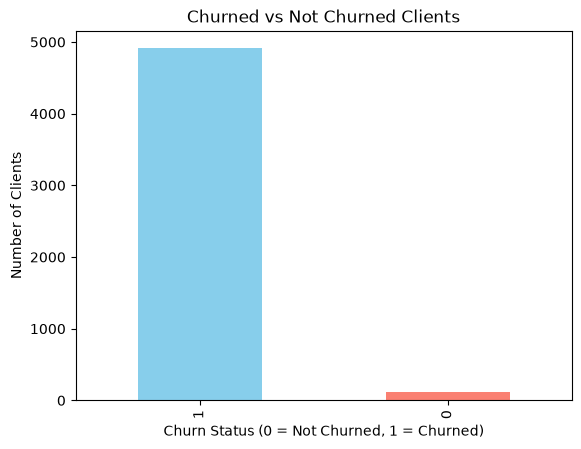

In [52]:
# How many have churned vs not churned
churn_counts = spine['churn'].value_counts()
churn_counts.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Churned vs Not Churned Clients')
plt.xlabel('Churn Status (0 = Not Churned, 1 = Churned)')
plt.ylabel('Number of Clients')
churn_counts